# BESS Operating Data: Data Quality Checks and Anomaly Detection

Synthetic telemetry from 20 LFP battery racks over 7 days at 1-minute resolution (about 200,000 rows).
The goal is to find sensor problems and abnormal racks, design alarm rules, and produce an operator-ready report.

## 1. Data Loading and First Look

Load the data, check types and completeness, and look at one rack's normal daily operation.

In [1]:
# Run once to generate the simulated data: %run make_bess_data.py

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

%time ops = pd.read_csv("../data/bess_ops.csv", parse_dates=["timestamp"])

CPU times: total: 609 ms
Wall time: 624 ms


In [3]:
ops.shape

(201600, 9)

In [4]:
ops.head(5)

,timestamp,rack_id,soc_pct,current_A,rack_voltage_V,max_cell_V,min_cell_V,max_temp_C,ambient_C
0,2026-07-01,R01,14.9808,-1.5516,770.3194,3.2137,3.2056,22.3706,26.263
1,2026-07-01,R02,15.1449,1.0514,770.1731,3.2135,3.2046,22.1374,26.263
2,2026-07-01,R03,14.8819,-0.9048,770.1994,3.2128,3.2055,21.2896,26.263
3,2026-07-01,R04,15.0302,0.5633,770.1526,3.2125,3.2054,22.5790,26.263
4,2026-07-01,R05,14.7098,1.0405,769.9117,3.2124,3.2035,22.0013,26.263


In [5]:
ops.dtypes

timestamp         datetime64[us]
rack_id                      str
soc_pct                  float64
current_A                float64
rack_voltage_V           float64
max_cell_V               float64
min_cell_V               float64
max_temp_C               float64
ambient_C                float64
dtype: object

In [6]:
ops["rack_id"].unique()

<ArrowStringArray>
['R01', 'R02', 'R03', 'R04', 'R05', 'R06', 'R07', 'R08', 'R09', 'R10', 'R11',
 'R12', 'R13', 'R14', 'R15', 'R16', 'R17', 'R18', 'R19', 'R20']
Length: 20, dtype: str

In [7]:
ops["timestamp"].min(), ops["timestamp"].max()

(Timestamp('2026-07-01 00:00:00'), Timestamp('2026-07-07 23:59:00'))

In [8]:
ops.describe().round(2)

,timestamp,soc_pct,current_A,rack_voltage_V,max_cell_V,min_cell_V,max_temp_C,ambient_C
count,201600,201420.00,201420.00,201420.00,201420.00,201420.00,201420.00,201600.00
mean,2026-07-04 11:59:29.999999,32.89,0.04,770.47,3.21,3.20,27.62,29.00
min,2026-07-01 00:00:00,4.18,-144.23,734.96,3.07,2.99,19.10,24.17
25%,2026-07-02 17:59:45,5.04,-1.15,752.12,3.14,3.13,22.29,26.19
50%,2026-07-04 11:59:30,6.83,0.00,754.16,3.15,3.14,26.16,29.01
75%,2026-07-06 05:59:15,64.52,1.15,789.39,3.29,3.28,33.43,31.82
max,2026-07-07 23:59:00,98.78,144.59,831.63,3.47,3.46,120.00,34.20
std,NaN,36.31,80.84,23.73,0.10,0.10,5.62,2.85


In [9]:
ops.groupby("rack_id").size()

rack_id
R01    10080
R02    10080
R03    10080
R04    10080
R05    10080
R06    10080
R07    10080
R08    10080
R09    10080
R10    10080
R11    10080
R12    10080
R13    10080
R14    10080
R15    10080
R16    10080
R17    10080
R18    10080
R19    10080
R20    10080
dtype: int64

In [10]:
ops.groupby("rack_id")["soc_pct"].count()

rack_id
R01    10080
R02     9900
R03    10080
R04    10080
R05    10080
R06    10080
R07    10080
R08    10080
R09    10080
R10    10080
R11    10080
R12    10080
R13    10080
R14    10080
R15    10080
R16    10080
R17    10080
R18    10080
R19    10080
R20    10080
Name: soc_pct, dtype: int64

In [11]:
r03_day = ops[(ops["timestamp"] >= "2026-07-02") & (ops["timestamp"] < "2026-07-03") & (ops["rack_id"] == "R03")]
r03_day.shape

(1440, 9)

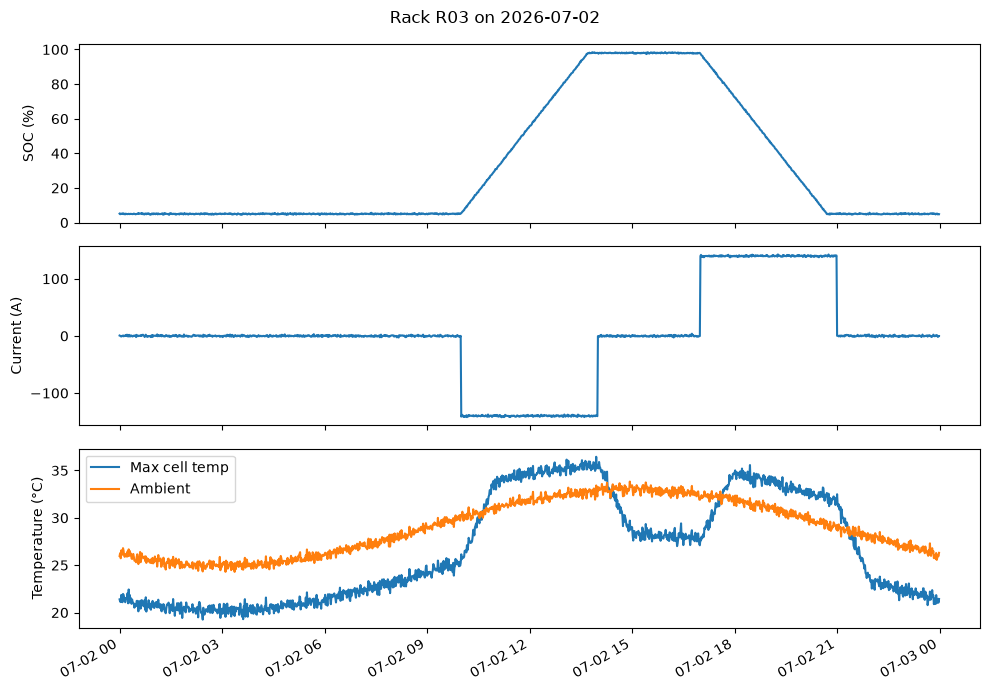

In [12]:
# plotting SOC, current and temperature for R03 on 2026-07-02 

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

axes[0].plot(r03_day["timestamp"], r03_day["soc_pct"])
axes[0].set_ylabel("SOC (%)")

axes[1].plot(r03_day["timestamp"], r03_day["current_A"])
axes[1].set_ylabel("Current (A)")

axes[2].plot(r03_day["timestamp"], r03_day["max_temp_C"], label="Max cell temp")
axes[2].plot(r03_day["timestamp"], r03_day["ambient_C"], label="Ambient")
axes[2].set_ylabel("Temperature (°C)")
axes[2].legend()

fig.suptitle("Rack R03 on 2026-07-02")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Finding:** Charging runs 10:00–14:00 and discharging 17:00–21:00. Temperature lags current by about one hour,
and cells stay below ambient because the cooling system runs continuously.

## 2. Data Quality Checks and Cleaning

Four types of data problems are checked: missing data, out-of-range readings, spikes, and stuck sensors.
Raw data is never overwritten; bad readings are masked in `temp_clean`, and `temp_flag` records the reason.

### 2.1 Missing data

In [13]:
# check the missing data

ops.isna().sum()

timestamp           0
rack_id             0
soc_pct           180
current_A         180
rack_voltage_V    180
max_cell_V        180
min_cell_V        180
max_temp_C        180
ambient_C           0
dtype: int64

In [14]:
# missing data: start time, end time and duration

missing = ops[ops["soc_pct"].isna()]
missing.groupby("rack_id").agg(
    start = ("timestamp", "min"),
    end = ("timestamp", "max"),
    n_rows = ("timestamp", "size"),
)

,start,end,n_rows
rack_id,,,
R02,2026-07-05 13:00:00,2026-07-05 15:59:00,180


### 2.2 Out-of-range readings and spikes

In [15]:
# sort as rack_id and timestamp

ops = ops.sort_values(["rack_id", "timestamp"]).reset_index(drop=True)
ops.head()

,timestamp,rack_id,soc_pct,current_A,rack_voltage_V,max_cell_V,min_cell_V,max_temp_C,ambient_C
0,2026-07-01 00:00:00,R01,14.9808,-1.5516,770.3194,3.2137,3.2056,22.3706,26.2630
1,2026-07-01 00:01:00,R01,14.9791,-0.2193,770.1966,3.2135,3.2048,21.2329,25.8473
2,2026-07-01 00:02:00,R01,15.5010,1.7924,770.3114,3.2135,3.2058,22.3760,26.3721
3,2026-07-01 00:03:00,R01,14.9320,0.1314,770.1364,3.2134,3.2045,22.2340,26.4170
4,2026-07-01 00:04:00,R01,15.1993,-0.5646,770.3570,3.2141,3.2055,21.3230,25.5373


In [16]:
# check out-of-range temperature

out_of_range = ops[(ops["max_temp_C"] < -20) | (ops["max_temp_C"] > 70)]
out_of_range

,timestamp,rack_id,soc_pct,current_A,rack_voltage_V,max_cell_V,min_cell_V,max_temp_C,ambient_C
100897,2026-07-01 01:37:00,R11,14.9970,-0.0882,770.1953,3.2134,3.2049,120.0,24.9603
101291,2026-07-01 08:11:00,R11,15.2525,1.6176,770.1863,3.2131,3.2051,120.0,28.2612
103121,2026-07-02 14:41:00,R11,97.7254,-0.4399,811.8812,3.3871,3.3785,120.0,33.3636
104492,2026-07-03 13:32:00,R11,93.6298,-139.4679,810.6851,3.3818,3.3739,85.0,32.1271
104746,2026-07-03 17:46:00,R11,78.3101,140.5313,773.9637,3.2282,3.2215,85.0,32.3882
109022,2026-07-06 17:02:00,R11,96.8865,138.9645,794.9375,3.3163,3.3082,85.0,32.1754


In [17]:
ops["temp_jump"] = ops.groupby("rack_id")["max_temp_C"].diff()
ops["temp_jump"].abs().describe()

count    201399.000000
mean          0.446531
std           0.671276
min           0.000000
25%           0.175800
50%           0.374500
75%           0.638700
max          98.770600
Name: temp_jump, dtype: float64

In [18]:
# temp_jump over 10C

spikes = ops[ops["temp_jump"].abs() > 10]
spikes[["timestamp", "rack_id", "max_temp_C", "temp_jump"]]

,timestamp,rack_id,max_temp_C,temp_jump
100897,2026-07-01 01:37:00,R11,120.0000,98.7706
100898,2026-07-01 01:38:00,R11,21.9929,-98.0071
101291,2026-07-01 08:11:00,R11,120.0000,94.7685
101292,2026-07-01 08:12:00,R11,24.5875,-95.4125
103121,2026-07-02 14:41:00,R11,120.0000,87.4954
103122,2026-07-02 14:42:00,R11,31.5799,-88.4201
104492,2026-07-03 13:32:00,R11,85.0000,48.3051
104493,2026-07-03 13:33:00,R11,36.3011,-48.6989
104746,2026-07-03 17:46:00,R11,85.0000,50.3137
104747,2026-07-03 17:47:00,R11,34.5995,-50.4005


**Finding:** R02 lost communication for 3 hours on Jul 5 (all rack fields missing while ambient still reported).
R11 has six isolated one-minute readings of 85–120 °C with all other signals normal, which points to a faulty
sensor rather than real overheating.

### 2.3 Stuck sensor detection

In [19]:
# when temp sensor get stuck, the temperature does not change, junp == 0

ops[ops["temp_jump"] == 0]

,timestamp,rack_id,soc_pct,current_A,rack_voltage_V,max_cell_V,min_cell_V,max_temp_C,ambient_C,temp_jump
21297,2026-07-01 18:57:00,R03,48.4571,138.9280,767.1733,3.2002,3.1929,33.8473,31.0563,0.0
22203,2026-07-02 10:03:00,R03,6.5136,-140.6815,770.4021,3.2131,3.2069,25.8195,29.8567,0.0
62860,2026-07-02 15:40:00,R07,97.9208,-0.5419,812.9634,3.3916,3.3831,29.2009,32.8571,0.0
72703,2026-07-02 11:43:00,R08,48.5062,-140.5815,793.2566,3.3090,3.3015,35.9842,31.7293,0.0
103812,2026-07-03 02:12:00,R11,5.1449,-0.1962,752.6744,3.1406,3.1317,21.6874,24.9611,0.0
...,...,...,...,...,...,...,...,...,...,...
155279,2026-07-03 19:59:00,R16,23.2990,139.5373,760.0154,3.1715,3.1620,23.7463,29.8991,0.0
161967,2026-07-01 11:27:00,R17,51.7874,-139.8398,793.4389,3.3109,3.3011,34.9707,31.8428,0.0
168404,2026-07-05 22:44:00,R17,5.1607,0.0141,752.7238,3.1402,3.1325,23.1791,27.2296,0.0
170725,2026-07-07 13:25:00,R17,91.1166,-139.3611,806.7400,3.3657,3.3571,36.3316,32.8204,0.0


In [20]:
ops[ops["temp_jump"] == 0].groupby("rack_id").size()

rack_id
R03      2
R07      1
R08      1
R11      2
R13      1
R14      1
R16    719
R17      3
R19      1
dtype: int64

In [21]:
# sensor stuck: start time, end time and duration

temp_jump_0 = ops[ops["temp_jump"] == 0]
temp_jump_0.groupby("rack_id").agg(
    start = ("timestamp", "min"),
    end = ("timestamp", "max"),
    n_rows = ("timestamp", "size"),
)

,start,end,n_rows
rack_id,,,
R03,2026-07-01 18:57:00,2026-07-02 10:03:00,2
R07,2026-07-02 15:40:00,2026-07-02 15:40:00,1
R08,2026-07-02 11:43:00,2026-07-02 11:43:00,1
R11,2026-07-03 02:12:00,2026-07-03 14:23:00,2
R13,2026-07-04 19:17:00,2026-07-04 19:17:00,1
R14,2026-07-01 17:01:00,2026-07-01 17:01:00,1
R16,2026-07-03 08:01:00,2026-07-03 19:59:00,719
R17,2026-07-01 11:27:00,2026-07-07 13:25:00,3
R19,2026-07-03 19:40:00,2026-07-03 19:40:00,1


In [22]:
# new column to show whether the temp_jump value is the same as the last row (min). True if the temperature is unchanged from the previous minute
ops["is_flat"] = ops["temp_jump"] == 0

# for each rack, count how many of the last 30 minutes were unchanged
ops["flat_count_30"] = ops.groupby("rack_id")["is_flat"].transform(
    lambda s: s.rolling(30).sum()
)

In [23]:
# stuck rule: temp_change == 0 for the last 30min
stuck_30 = ops[ops["flat_count_30"] == 30]
stuck_30.groupby("rack_id").agg(
    start = ("timestamp", "min"),
    end = ("timestamp", "max"),
    n_rows = ("timestamp", "size"),
)

,start,end,n_rows
rack_id,,,
R16,2026-07-03 08:30:00,2026-07-03 19:59:00,690


**Finding:** R16's temperature froze at 23.7 °C for 12 hours while the rack charged and discharged.
A stuck sensor passes range and spike checks, so an over-temperature alarm could not have fired during that time.

In [24]:
# clean data, and put all data cleaning together
# 1. define the problem for max_temp
is_out_of_range = (ops["max_temp_C"] < -20) | (ops["max_temp_C"] > 70)
is_stuck = (ops["flat_count_30"] == 30)

# 2. mask all problem data for max_temp including "is_out_of_range" and "is_stuck"
ops["temp_clean"] = ops["max_temp_C"].mask(is_out_of_range | is_stuck)

# 3. mark the data. set all as "ok", then set for each problem
ops["temp_flag"] = "ok"
ops.loc[ops["max_temp_C"].isna(), "temp_flag"] = "missing"
ops.loc[is_out_of_range, "temp_flag"] = "out_of_range"
ops.loc[is_stuck, "temp_flag"] = "stuck"

In [25]:
ops["temp_flag"].value_counts()

temp_flag
ok              200724
stuck              690
missing            180
out_of_range         6
Name: count, dtype: int64

## 3. Rule-Based Alarms with Persistence

An alarm fires only if a condition holds for a sustained window. Using the rolling minimum means
isolated spikes cannot trigger an alarm.

In [26]:
# single point alarm: alarm when temp > 40C
single_alarm = ops[ops["max_temp_C"] > 40]
single_alarm.groupby("rack_id").size()

rack_id
R07    969
R11      6
dtype: int64

In [27]:
# set a column for the minimum max_temp in the last 10 min 
ops["temp_min_10"] = ops.groupby("rack_id")["max_temp_C"].transform(
    lambda s:s.rolling(10).min()
)

In [28]:
# sustained alarm: the minimum max_temp > 40C last for over 10min
sustained_alarm = ops[ops["temp_min_10"] > 40]
sustained_alarm.groupby("rack_id").agg(
    first = ("timestamp", "min"),
    n_rows = ("timestamp","size"),
)

,first,n_rows
rack_id,,
R07,2026-07-05 13:50:00,806


**Finding:** The persistence condition removes all of R11's spike alarms. R07's first alarm moves from 11:25 to 13:50
on Jul 5. The delay is much longer than the 10-minute window because R07's temperature drifted slowly around 40 °C.

In [29]:
# new column: spread_mV = (max_cell_V - min_cell_V) * 1000
# check median and maximum of spread_mV for each rack, to see the normal range
# then write a rule to check spread_mV > 30mV for over 10min, find the rack and the first time of the alarm

ops["spread_mV"] = (ops["max_cell_V"] - ops["min_cell_V"]) * 1000

display(ops.groupby("rack_id").agg(
    median_mV = ("spread_mV", "median"),
    max_mV = ("spread_mV", "max"),
))

,median_mV,max_mV
rack_id,,
R01,8.0,12.0
R02,8.0,12.0
R03,8.0,11.8
R04,8.0,11.7
R05,8.0,11.7
R06,8.0,12.0
R07,8.0,11.8
R08,8.0,11.2
R09,8.0,12.0


In [30]:
# generate a column for minimum of spread_mV in last 10min
ops["spread_min_10"] = ops.groupby("rack_id")["spread_mV"].transform(
    lambda s:s.rolling(10).min()
)

# set a sustained alarm for spread_mV
sustain_V_alarm = ops[ops["spread_min_10"] > 30]
sustain_V_alarm.groupby("rack_id").agg(
    first = ("timestamp", "min")
)

,first
rack_id,
R13,2026-07-03 21:57:00


In [31]:
# check the cleaned maximum of max_temp for rack01, 07 and 12 for each day
ops["date"] = ops["timestamp"].dt.date
daily_max = ops.groupby(["rack_id", "date"])["temp_clean"].max().unstack()
daily_max.loc[["R01", "R07", "R12"]].round(1)

date,2026-07-01,2026-07-02,2026-07-03,2026-07-04,2026-07-05,2026-07-06,2026-07-07
rack_id,,,,,,,
R01,37.0,36.7,36.9,37.0,37.0,37.0,37.2
R07,37.5,37.9,37.6,38.8,41.2,43.8,45.4
R12,37.2,37.3,37.0,37.3,37.4,37.4,37.3


**Finding:** R07 was already clearly hotter than other racks on Jul 4, but the fixed 40 °C threshold did not alarm
until the afternoon of Jul 5. Fixed thresholds catch problems only once they are severe.

## 4. Peer Comparison with Robust Z-Scores

Each rack is compared with the fleet median at the same minute. The deviation is scaled by the
median absolute deviation (MAD), so the faulty rack cannot inflate the scale and mask itself.

In [32]:
# select a midian temperature for 20 racks at each min, as a baseline

ops["fleet_median"] = ops.groupby("timestamp")["temp_clean"].transform("median")
ops["temp_dev"] = ops["temp_clean"] - ops["fleet_median"]

In [33]:
# check the average temperature deviation for each rack on each day
ops.groupby(["rack_id","date"])["temp_dev"].mean().unstack().round(2)

date,2026-07-01,2026-07-02,2026-07-03,2026-07-04,2026-07-05,2026-07-06,2026-07-07
rack_id,,,,,,,
R01,-0.07,-0.07,-0.07,-0.07,-0.07,-0.07,-0.08
R02,-0.72,-0.73,-0.73,-0.74,-0.72,-0.72,-0.74
R03,-0.73,-0.75,-0.74,-0.73,-0.75,-0.73,-0.75
R04,0.29,0.30,0.29,0.30,0.28,0.30,0.30
R05,-0.18,-0.19,-0.18,-0.19,-0.20,-0.20,-0.19
R06,0.02,0.04,0.02,0.03,0.03,0.02,0.02
R07,0.36,0.37,0.34,1.61,4.11,6.61,8.29
R08,0.13,0.15,0.13,0.14,0.14,0.16,0.13
R09,0.17,0.17,0.15,0.15,0.16,0.17,0.17


In [34]:
# z = (value − baseline) ÷ std, z means how many times of std the value deviated
# for a normal distribution), the chance of |z| > 3 is only 0.3%. so 3 is the usually the boundary of abnormal
# no matter the unit, such as ℃、mV or A, the z-score could be used to determine how much it deviated.

ops["fleet_std"] = ops.groupby("timestamp")["temp_clean"].transform("std")
ops["temp_z"] = ops["temp_dev"] / ops["fleet_std"]

ops.groupby(["rack_id","date"])["temp_z"].mean().unstack().round(2)

date,2026-07-01,2026-07-02,2026-07-03,2026-07-04,2026-07-05,2026-07-06,2026-07-07
rack_id,,,,,,,
R01,-0.16,-0.16,-0.14,-0.12,-0.07,-0.05,-0.04
R02,-1.64,-1.63,-1.64,-1.30,-0.73,-0.47,-0.39
R03,-1.66,-1.68,-1.67,-1.30,-0.75,-0.48,-0.39
R04,0.66,0.67,0.66,0.53,0.28,0.20,0.16
R05,-0.41,-0.43,-0.41,-0.34,-0.20,-0.13,-0.10
R06,0.05,0.09,0.06,0.04,0.03,0.02,0.01
R07,0.82,0.82,0.76,2.63,3.98,4.26,4.34
R08,0.30,0.33,0.29,0.25,0.14,0.10,0.07
R09,0.38,0.38,0.34,0.26,0.16,0.11,0.09


In [35]:
# add sustained alarm

ops["z_min_30"] = ops.groupby("rack_id")["temp_z"].transform(
    lambda s: s.rolling(30).min()
)

In [36]:
# alarm when z-score > 3 last for 30min 

z_alarm = ops[ops["z_min_30"] > 3]
z_alarm.groupby("rack_id").agg(
    first = ("timestamp", "min"),
    n_rows = ("timestamp","size"),
)

,first,n_rows
rack_id,,
R07,2026-07-04 18:14:00,4415


In [37]:
pd.Timestamp("2026-07-05 13:50") - pd.Timestamp("2026-07-04 18:14:00")

Timedelta('0 days 19:36:00')

In [38]:
# masking effect: large R07 temperature change leads to large std, making z-score smaller even when temperature increase a lot
# so use robust z-score, by replacing std with median absolute deviation (MAD)

ops["abs_dev"] = ops["temp_dev"].abs()
ops["fleet_mad"] = ops.groupby("timestamp")["abs_dev"].transform("median")
ops["robust_z"] = 0.6745 * ops["temp_dev"] / ops["fleet_mad"]

ops.groupby(["rack_id", "date"])["robust_z"].mean().unstack().round(2)

date,2026-07-01,2026-07-02,2026-07-03,2026-07-04,2026-07-05,2026-07-06,2026-07-07
rack_id,,,,,,,
R01,-0.17,-0.17,-0.16,-0.16,-0.17,-0.17,-0.18
R02,-1.86,-1.84,-1.87,-1.79,-1.75,-1.72,-1.78
R03,-1.89,-1.90,-1.90,-1.78,-1.83,-1.76,-1.80
R04,0.72,0.73,0.73,0.70,0.66,0.69,0.70
R05,-0.44,-0.46,-0.45,-0.44,-0.46,-0.45,-0.44
R06,0.05,0.09,0.06,0.06,0.06,0.06,0.05
R07,0.90,0.91,0.84,3.90,10.01,15.89,20.10
R08,0.31,0.36,0.31,0.32,0.31,0.35,0.29
R09,0.41,0.41,0.36,0.34,0.35,0.38,0.38


In [39]:
# add sustained alarm 

ops["robust_z_min_30"] = ops.groupby("rack_id")["robust_z"].transform(
    lambda s: s.rolling(30).min()
)
robust_z_alarm = ops[ops["robust_z_min_30"] > 3]
robust_z_alarm.groupby("rack_id").agg(
    first = ("timestamp", "min"),
    n_rows = ("timestamp","size"),
)

,first,n_rows
rack_id,,
R07,2026-07-04 13:46:00,4760


In [40]:
pd.Timestamp("2026-07-04 18:14:00") - pd.Timestamp("2026-07-04 13:46:00")

Timedelta('0 days 04:28:00')

**Finding:** Peer comparison detects R07's cooling failure much earlier than a fixed threshold, with no false alarms on any other rack.

| Method | First alarm (R07) | Earlier than fixed threshold |
|---|---|---|
| Fixed threshold (40 °C, sustained 10 min) | Jul 5, 13:50 | — |
| Standard z-score (z > 3, sustained 30 min) | Jul 4, 18:14 | ~19.5 h |
| Robust z-score (z > 3, sustained 30 min) | Jul 4, 13:46 | ~24 h |

- **Masking effect:** the standard z-score uses the fleet standard deviation, which includes R07 itself. As R07 heats up it inflates the standard deviation, so its own z-score levels off around 4 even though its deviation keeps growing. The robust z-score uses the median absolute deviation, which R07 cannot inflate, so it rises steadily (daily mean of about 20 by Jul 7).
- **Rack offsets:** some healthy racks sit consistently above or below the fleet (robust z near −1.9 for R02 and R03, +1.2 to +1.7 for R11 and R18). They stay below the threshold here, but the margin is small. Subtracting each rack's own baseline would make the rule more robust on a larger site. 

## 5. Reporting

Fleet heatmaps, a combined alarm summary, a daily report, and an Excel export for colleagues.

### 5.1 Fleet heatmaps

In [41]:
# temperature deviation heatmap

ops["hour"] = ops["timestamp"].dt.floor("h")
hourly_dev = ops.groupby(["rack_id", "hour"])["temp_dev"].mean().unstack()
hourly_dev.shape

(20, 168)

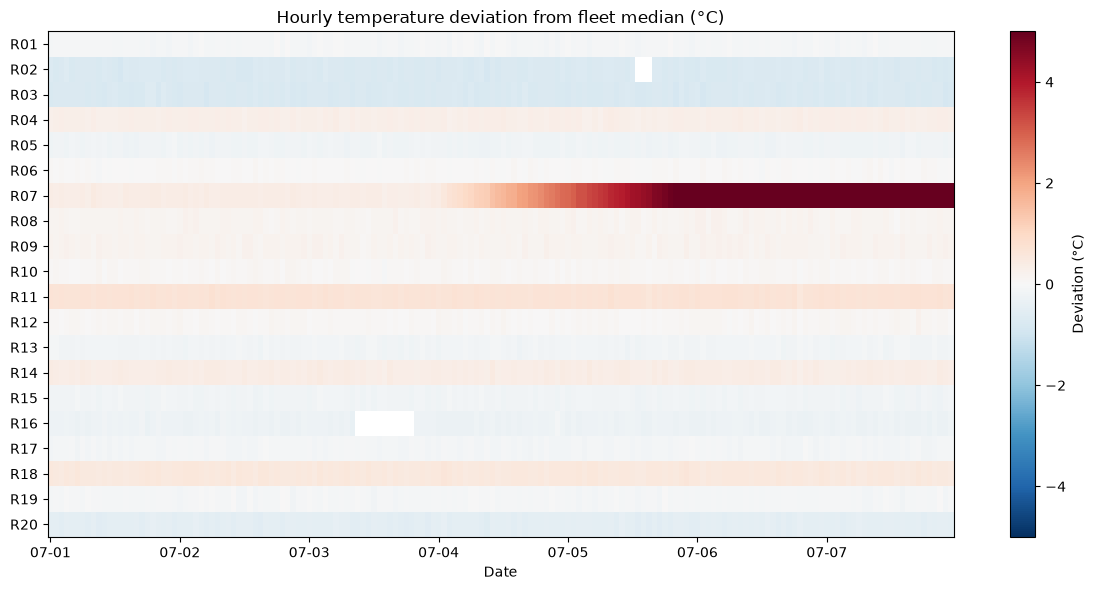

In [42]:
# plotting temperature deviation heatmap

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(hourly_dev, aspect="auto", cmap="RdBu_r", vmin=-5, vmax=5)

ax.set_yticks(range(len(hourly_dev.index)))
ax.set_yticklabels(hourly_dev.index)

day_starts = range(0, hourly_dev.shape[1], 24)
ax.set_xticks(day_starts)
ax.set_xticklabels([hourly_dev.columns[i].strftime("%m-%d") for i in day_starts])

ax.set_xlabel("Date")
ax.set_title("Hourly temperature deviation from fleet median (°C)")
fig.colorbar(im, ax=ax, label="Deviation (°C)")
plt.tight_layout()
fig.savefig("../data/temperature_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

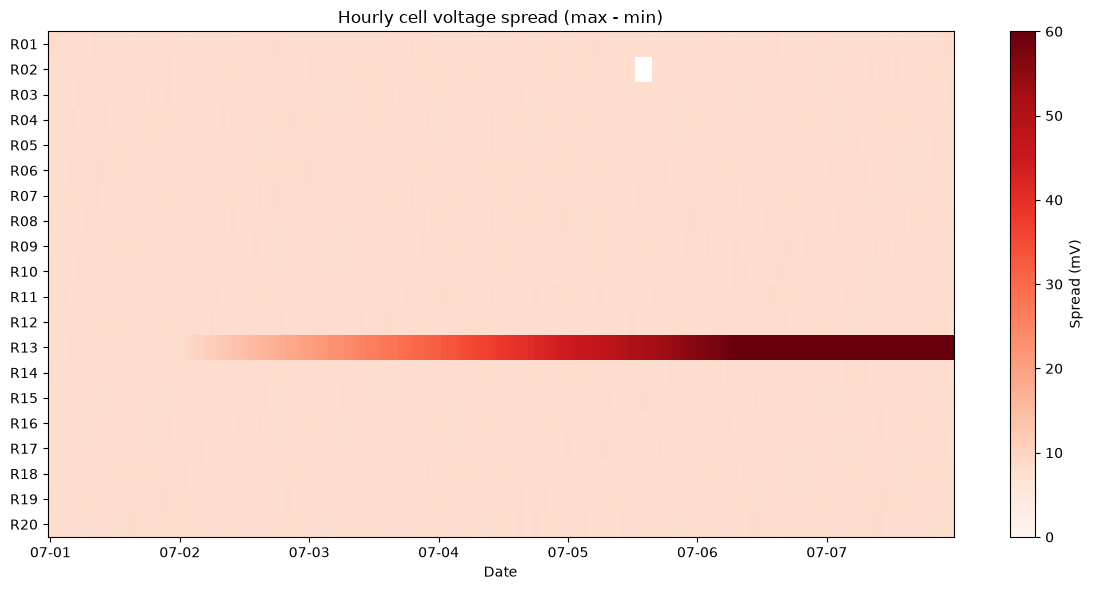

In [43]:
# cell voltage spread heatmap

ops["hour"] = ops["timestamp"].dt.floor("h")
hourly_mV_dev = ops.groupby(["rack_id", "hour"])["spread_mV"].mean().unstack()
hourly_mV_dev.shape

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(hourly_mV_dev, aspect="auto", cmap="Reds", vmin=0, vmax=60)

ax.set_yticks(range(len(hourly_mV_dev.index)))
ax.set_yticklabels(hourly_mV_dev.index)

day_starts = range(0, hourly_mV_dev.shape[1], 24)
ax.set_xticks(day_starts)
ax.set_xticklabels([hourly_mV_dev.columns[i].strftime("%m-%d") for i in day_starts])

ax.set_xlabel("Date")
ax.set_title("Hourly cell voltage spread (max - min)")
fig.colorbar(im, ax=ax, label="Spread (mV)")
plt.tight_layout()
fig.savefig("../data/voltage_spread_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

### 5.2 Alarm summary

In [44]:
# put repeated codes as a def

def summarize(condition, alarm_name):
    hits = ops[condition]
    table = hits.groupby("rack_id").agg(
        first=("timestamp", "min"),
        last=("timestamp", "max"),
        n_minutes=("timestamp", "size"),
    ).reset_index()
    table["alarm"] = alarm_name
    return table

In [45]:
# put all rules in a dict
alarm_rules = {
    "Communication loss": ops["soc_pct"].isna(),
    "Sensor out of range": is_out_of_range,
    "Temperature sensor stuck": is_stuck,
    "Over-temperature": ops["temp_min_10"] > 40,
    "Abnormal temperature vs fleet": ops["robust_z_min_30"] > 3,
    "Cell voltage imbalance": ops["spread_min_10"] > 30,
}

In [46]:
# apply summarize() to every rule

tables = []
for name, condition in alarm_rules.items():
    tables.append(summarize(condition, name))

alarm_summary = pd.concat(tables, ignore_index=True).sort_values("first")
alarm_summary

,rack_id,first,last,n_minutes,alarm
1,R11,2026-07-01 01:37:00,2026-07-06 17:02:00,6,Sensor out of range
2,R16,2026-07-03 08:30:00,2026-07-03 19:59:00,690,Temperature sensor stuck
5,R13,2026-07-03 21:57:00,2026-07-07 23:59:00,5785,Cell voltage imbalance
4,R07,2026-07-04 13:46:00,2026-07-07 23:59:00,4760,Abnormal temperature vs fleet
0,R02,2026-07-05 13:00:00,2026-07-05 15:59:00,180,Communication loss
3,R07,2026-07-05 13:50:00,2026-07-07 20:59:00,806,Over-temperature


In [47]:
# event summary

hits = ops[is_out_of_range].copy()
hits["new_event"] = hits.groupby("rack_id")["timestamp"].diff() != pd.Timedelta("1min")
hits["event_id"] = hits.groupby("rack_id")["new_event"].cumsum()
hits.groupby(["rack_id", "event_id"]).agg(
    start=("timestamp", "min"),
    end=("timestamp", "max"),
    n_minutes=("timestamp", "size"),
)


start                 end  n_minutes
rack_id event_id                                                   
R11     1        2026-07-01 01:37:00 2026-07-01 01:37:00          1
        2        2026-07-01 08:11:00 2026-07-01 08:11:00          1
        3        2026-07-02 14:41:00 2026-07-02 14:41:00          1
        4        2026-07-03 13:32:00 2026-07-03 13:32:00          1
        5        2026-07-03 17:46:00 2026-07-03 17:46:00          1
        6        2026-07-06 17:02:00 2026-07-06 17:02:00          1

### 5.3 Daily report and export

In [48]:
# data avaibility

availability = ops.groupby("rack_id")["soc_pct"].count() / ops.groupby("rack_id").size() * 100
availability.round(2).sort_values()

rack_id
R02     98.21
R01    100.00
R03    100.00
R04    100.00
R05    100.00
R06    100.00
R07    100.00
R08    100.00
R09    100.00
R10    100.00
R11    100.00
R12    100.00
R13    100.00
R14    100.00
R15    100.00
R16    100.00
R17    100.00
R18    100.00
R19    100.00
R20    100.00
dtype: float64

In [49]:
def daily_report(day):
    is_day = ops["date"] == pd.Timestamp(day).date()
    day_data = ops[is_day]
    availability = day_data["soc_pct"].notna().mean() * 100

    print(f"===== Daily report: {day} =====")
    print(f"Data availability: {availability:.1f}%")
    print(f"Highest cell temperature: {day_data['temp_clean'].max():.1f} °C")

    tables = []
    for name, condition in alarm_rules.items():
        tables.append(summarize(condition & is_day, name))
    display(pd.concat(tables, ignore_index=True))

daily_report("2026-07-05")

===== Daily report: 2026-07-05 =====
Data availability: 99.4%
Highest cell temperature: 41.2 °C


,rack_id,first,last,n_minutes,alarm
0,R02,2026-07-05 13:00:00,2026-07-05 15:59:00,180,Communication loss
1,R07,2026-07-05 13:50:00,2026-07-05 14:04:00,15,Over-temperature
2,R07,2026-07-05 00:00:00,2026-07-05 23:59:00,1440,Abnormal temperature vs fleet
3,R13,2026-07-05 00:00:00,2026-07-05 23:59:00,1440,Cell voltage imbalance


In [50]:
# export data and figure

with pd.ExcelWriter("../data/bess_report.xlsx") as writer:
    alarm_summary.to_excel(writer, sheet_name="Alarms", index=False)
    availability.round(2).to_excel(writer, sheet_name="Availability")

## 6. Summary

- Robust peer comparison detected R07's cooling failure about 24 hours earlier than a fixed 40 °C threshold, with no false alarms.
- A stuck sensor is more dangerous than a noisy one because it looks normal.
- Fixed thresholds lag trends; both R07 and R13 were visible on the heatmaps more than a day before their fixed-threshold alarms.